# Lood data 
# Show sample

Number of images: 202599
(178, 218)
(178, 218)
(178, 218)
(178, 218)


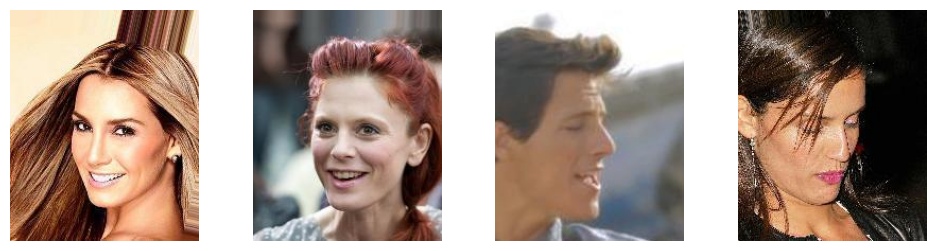

In [1]:
import glob
import matplotlib.pyplot as plt
from PIL import Image

DATA_ROOT = "/kaggle/input/datasets/jessicali9530/celeba-dataset"

paths = sorted(glob.glob(DATA_ROOT + "/**/*.jpg", recursive=True))
print("Number of images:", len(paths))

fig, axs = plt.subplots(1, 4, figsize=(12, 3))
for ax, p in zip(axs, paths[:4]):
    img = Image.open(p)
    ax.imshow(img); ax.axis("off")
    print(img.size)
plt.show()

# Preprocessing

Batch shape: (128, 64, 64, 3)
Min: -1.0 | Max: 1.0000004768371582


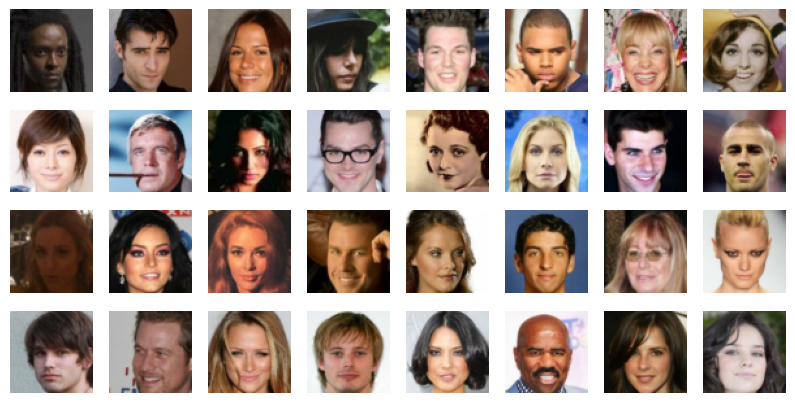

In [5]:
import random
import numpy as np
import tensorflow as tf

IMG_SIZE = 64
BATCH_SIZE = 128
N_IMAGES = 50000

random.seed(42)
subset_paths = random.sample(paths, N_IMAGES)

def load_and_preprocess(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.crop_to_bounding_box(img, 35, 15, 148, 148)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), antialias=True)
    img = (tf.cast(img, tf.float32) / 127.5) - 1.0
    return img

dataset = (tf.data.Dataset.from_tensor_slices(subset_paths)
           .shuffle(10000, seed=42)
           .map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH_SIZE, drop_remainder=True)
           .prefetch(tf.data.AUTOTUNE))

batch = next(iter(dataset))
print("Batch shape:", batch.shape)
print("Min:", float(tf.reduce_min(batch)), "| Max:", float(tf.reduce_max(batch)))

fig, axs = plt.subplots(4, 8, figsize=(10, 5))
for ax, img in zip(axs.flat, batch[:32]):
    ax.imshow(np.clip((img.numpy() + 1) / 2, 0, 1))
    axs_off = ax.axis("off")
plt.show()

# Build Generator

In [6]:
from tensorflow.keras import layers, models, initializers


NZ, NGF = 100, 64
init = initializers.RandomNormal(mean=0.0, stddev=0.02)

def build_generator():
    return models.Sequential([
        layers.Input(shape=(NZ,)),
        layers.Reshape((1, 1, NZ)),

        layers.Conv2DTranspose(NGF*8, 4, 1, "valid", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.ReLU(),

        layers.Conv2DTranspose(NGF*4, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.ReLU(),

        layers.Conv2DTranspose(NGF*2, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.ReLU(),

        layers.Conv2DTranspose(NGF, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.ReLU(),

        layers.Conv2DTranspose(3, 4, 2, "same", use_bias=False,
                               kernel_initializer=init, activation="tanh"),
    ], name="generator")

generator = build_generator()

z = tf.random.normal((16, NZ))
fake = generator(z, training=False)
print("Output shape:", fake.shape)
print("Min:", float(tf.reduce_min(fake)), "| Max:", float(tf.reduce_max(fake)))
print("Generator params:", generator.count_params())

Output shape: (16, 64, 64, 3)
Min: -0.01868443936109543 | Max: 0.014642046764492989
Generator params: 3578624


# Build Discriminator

In [7]:
NDF = 64

def build_discriminator():
    return models.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

        layers.Conv2D(NDF, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.LeakyReLU(0.2),

        layers.Conv2D(NDF*2, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),

        layers.Conv2D(NDF*4, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),

        layers.Conv2D(NDF*8, 4, 2, "same", use_bias=False, kernel_initializer=init),
        layers.BatchNormalization(), layers.LeakyReLU(0.2),

        layers.Flatten(),
        layers.Dense(1, kernel_initializer=init),
    ], name="discriminator")

discriminator = build_discriminator()

real_out = discriminator(batch[:16], training=False)
fake_out = discriminator(fake, training=False)
print("Output shape (real):", real_out.shape)
print("Output shape (fake):", fake_out.shape)
print("Discriminator params:", discriminator.count_params())

Output shape (real): (16, 1)
Output shape (fake): (16, 1)
Discriminator params: 2767361


# Loss, Optimizers and Training

In [9]:
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_out, fake_out):
    real_loss = bce(tf.ones_like(real_out), real_out)
    fake_loss = bce(tf.zeros_like(fake_out), fake_out)
    return real_loss + fake_loss

def generator_loss(fake_out):
    return bce(tf.ones_like(fake_out), fake_out)

g_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

fixed_noise = tf.random.normal((16, NZ), seed=1)

@tf.function
def train_step(real_images):
    noise = tf.random.normal((tf.shape(real_images)[0], NZ))
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_out)
        d_loss = discriminator_loss(real_out, fake_out)
        
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_opt.apply_gradients(zip(g_grads, generator.trainable_variables))
    d_opt.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

g_l, d_l = train_step(batch)
print("G loss:", float(g_l), "| D loss:", float(d_l))

G loss: 1.9058806896209717 | D loss: 2.154292345046997


# Train the GAN

In [11]:
import os, time

os.makedirs("/kaggle/working/samples", exist_ok=True)

EPOCHS = 20
g_losses, d_losses = [], []

def save_samples(epoch):
    imgs = generator(fixed_noise, training=False).numpy()
    imgs = np.clip((imgs + 1) / 2, 0, 1)
    fig, axs = plt.subplots(4, 4, figsize=(6, 6))
    for ax, img in zip(axs.flat, imgs):
        ax.imshow(img); ax.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/samples/epoch_{epoch:03d}.png", dpi=100)
    plt.close(fig)

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    g_sum, d_sum, n = 0.0, 0.0, 0
    for real_batch in dataset:
        g_l, d_l = train_step(real_batch)
        g_sum += float(g_l); d_sum += float(d_l); n += 1
    g_losses.append(g_sum / n); d_losses.append(d_sum / n)
    save_samples(epoch)
    print(f"Epoch {epoch:02d}/{EPOCHS} | G: {g_losses[-1]:.3f} | D: {d_losses[-1]:.3f} | {time.time()-start:.0f}s")

generator.save("/kaggle/working/generator.keras")

Epoch 01/20 | G: 2.736 | D: 0.691 | 64s
Epoch 02/20 | G: 2.621 | D: 0.694 | 64s
Epoch 03/20 | G: 2.659 | D: 0.593 | 64s
Epoch 04/20 | G: 2.756 | D: 0.525 | 64s
Epoch 05/20 | G: 3.010 | D: 0.527 | 64s
Epoch 06/20 | G: 2.761 | D: 0.544 | 64s
Epoch 07/20 | G: 2.998 | D: 0.456 | 64s
Epoch 08/20 | G: 2.898 | D: 0.506 | 64s
Epoch 09/20 | G: 2.666 | D: 0.587 | 64s
Epoch 10/20 | G: 2.530 | D: 0.626 | 64s
Epoch 11/20 | G: 2.397 | D: 0.623 | 65s
Epoch 12/20 | G: 2.351 | D: 0.639 | 64s
Epoch 13/20 | G: 2.294 | D: 0.633 | 64s
Epoch 14/20 | G: 2.208 | D: 0.699 | 64s
Epoch 15/20 | G: 2.195 | D: 0.679 | 64s
Epoch 16/20 | G: 2.170 | D: 0.665 | 64s
Epoch 17/20 | G: 2.184 | D: 0.701 | 64s
Epoch 18/20 | G: 2.108 | D: 0.670 | 64s
Epoch 19/20 | G: 2.180 | D: 0.648 | 64s
Epoch 20/20 | G: 2.171 | D: 0.690 | 64s


# Monitor Losses and Compare Results Over Time

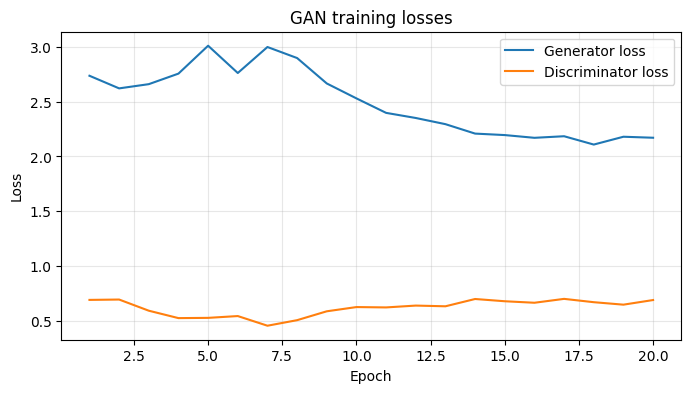

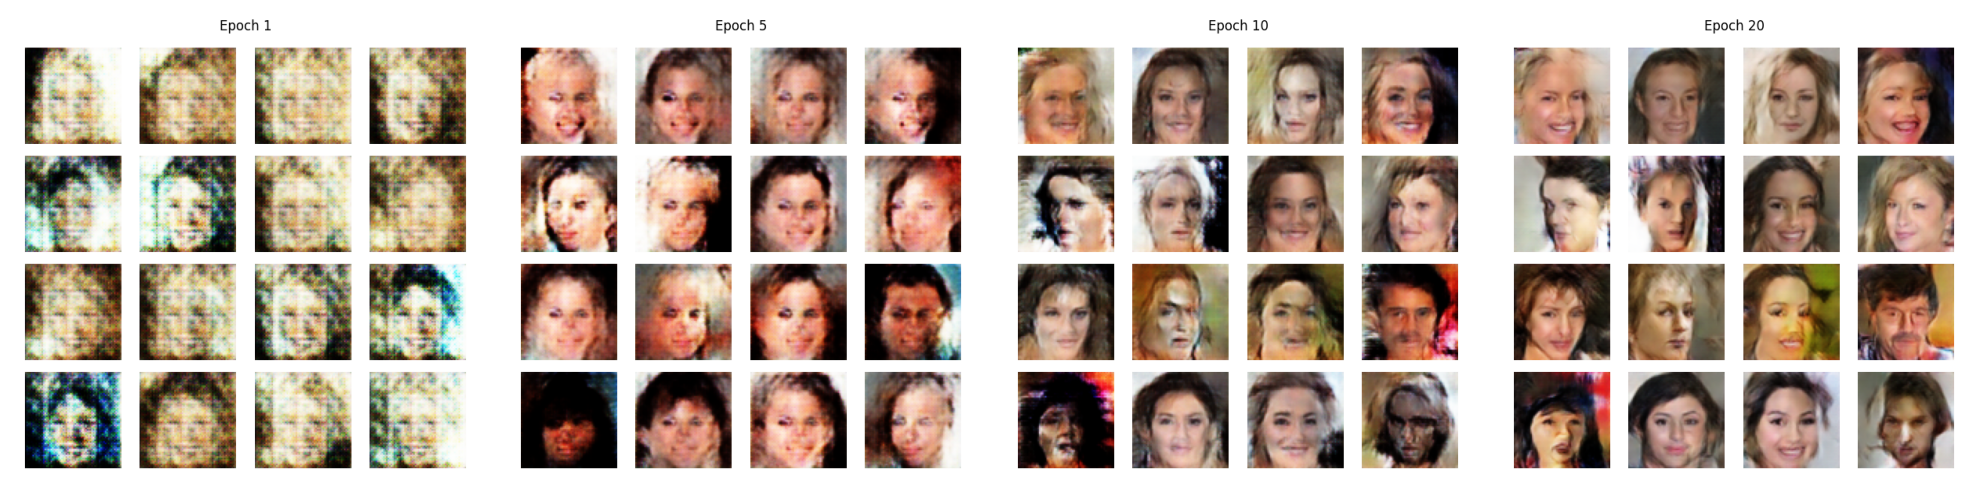

In [12]:
import matplotlib.image as mpimg

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(g_losses)+1), g_losses, label="Generator loss")
plt.plot(range(1, len(d_losses)+1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("GAN training losses")
plt.show()

epochs_to_show = [1, 5, 10, 20]
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
for ax, e in zip(axs, epochs_to_show):
    ax.imshow(mpimg.imread(f"/kaggle/working/samples/epoch_{e:03d}.png"))
    ax.axis("off")
plt.tight_layout()
plt.show()

# Final Generated Faces

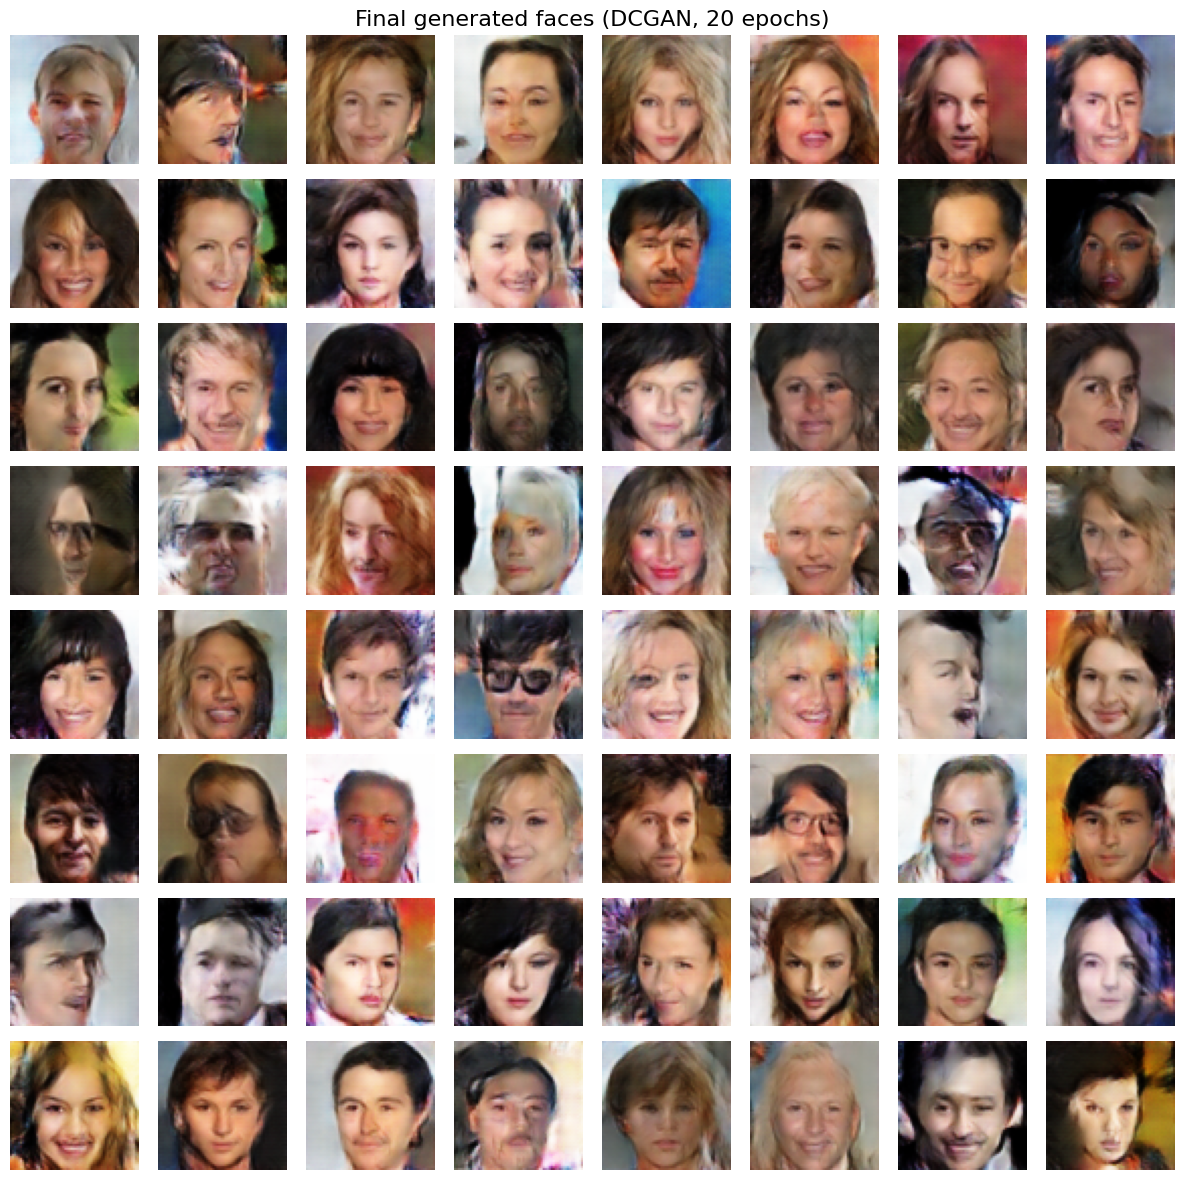

saved


In [13]:
final_noise = tf.random.normal((64, NZ))
final_imgs = generator(final_noise, training=False).numpy()
final_imgs = np.clip((final_imgs + 1) / 2, 0, 1)

fig, axs = plt.subplots(8, 8, figsize=(12, 12))
for ax, img in zip(axs.flat, final_imgs):
    ax.imshow(img); ax.axis("off")
plt.suptitle("Final generated faces (DCGAN, 20 epochs)", fontsize=16)
plt.tight_layout()
plt.savefig("/kaggle/working/final_faces.png", dpi=120)
plt.show()

generator.save("/kaggle/working/generator.keras")
print("saved")

# Save Loss Plot and List Output Files

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(g_losses)+1), g_losses, label="Generator loss")
plt.plot(range(1, len(d_losses)+1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(alpha=0.3)
plt.title("GAN training losses")
plt.savefig("/kaggle/working/losses.png", dpi=120, bbox_inches="tight")
plt.close()

import os
for f in sorted(os.listdir("/kaggle/working")):
    print(f)

.virtual_documents
final_faces.png
generator.keras
losses.png
samples
